# Does speed out of a slant break translate to NFL separation?
**2027 NFL Big Data Bowl · Wide receivers · 2023–2025 rookie classes**

A receiver can run a fast 40 and still struggle to get open. Does measuring how quickly they gain speed after turning inside add anything to the stopwatch? In this sample, adding the slant measurement **increased** prediction error from **0.162 to 0.175 yards** across 15 receivers in the 2025 draft class. The difference is too uncertain to justify grading prospects on this measurement alone.

To rerun on Kaggle, attach the [competition dataset](https://www.kaggle.com/competitions/nfl-big-data-bowl-2027/data) and run all cells. Locally, set the `BDB_DATA_DIR` environment variable to the folder containing the four input CSVs.

In [1]:
from pathlib import Path
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

required = ['combine_tracking.csv', 'combine_results.csv', 'games.csv', 'player_play.csv', 'players.csv']
if os.getenv('BDB_DATA_DIR'):
    folder = Path(os.environ['BDB_DATA_DIR'])
else:
    roots = [Path.cwd(), Path.cwd() / 'upload']
    if Path('/kaggle/input').exists():
        roots.extend(p.parent for p in Path('/kaggle/input').rglob('combine_results.csv'))
    folder = next((p for p in roots if all((p / f).is_file() for f in required)), None)
if folder is None or not all((folder / f).is_file() for f in required):
    raise FileNotFoundError('Attach the competition files or set BDB_DATA_DIR to their folder.')

## 1. Find the same moment in each slant
The sensor records ten frames per second. I mark the first inward turn of at least 25 degrees sustained across two consecutive estimates after two yards of downfield movement. The measurement is the change in speed from that marker to five frames later, in yards per second. For receivers with multiple attempts, I use their median.

In [2]:
def measure_attempt(group):
    """Turn proxy for this left slant: motion downfield (+x) and inside (-y)."""
    g = group.sort_values("time")
    if len(g) < 10 or g[["x", "y", "s"]].isna().any().any():
        return None
    x, y, speed = (g[column].to_numpy() for column in ["x", "y", "s"])
    dt = pd.to_datetime(g.time).diff().dt.total_seconds().iloc[1:]
    if not np.allclose(dt, 0.1):
        return None
    # Two-frame displacement is less sensitive to jitter than a single step.
    dx = x[2:] - x[:-2]
    dy = y[2:] - y[:-2]
    angle = np.degrees(np.arctan2(-dy, dx))
    inside = (angle >= 25) & (dx > 0) & (x[1:-1] - x[0] >= 2)
    hits = np.flatnonzero(inside[:-1] & inside[1:])
    if not len(hits):
        return None
    turn = int(hits[0] + 1)
    if turn + 5 >= len(speed):
        return None
    return speed[turn + 5] - speed[turn], x - x[0], y[0] - y, turn


def sensors(folder):
    columns = ["draft_year", "nfl_id", "event_id", "entity_type", "drill_type",
               "drill_name", "time", "x", "y", "s"]
    chunks = pd.read_csv(folder / "combine_tracking.csv", usecols=columns, chunksize=100000)
    drill = pd.concat(c.query("entity_type == 'PLAYER' and drill_type == 'SKILL_DRILLS_WR' "
                              "and drill_name == 'SLANT_ROUTE_LEFT'") for c in chunks)
    records, paths = [], []
    attempts = drill.groupby(["draft_year", "nfl_id", "event_id"])
    for (year, player, _), frames in attempts:
        measured = measure_attempt(frames)
        if measured is not None:
            gain, x, y, turn = measured
            records.append((year, player, gain))
            paths.append((x, y, turn))
    print(f"Usable attempts: {len(records)}/{len(attempts)}")
    features = pd.DataFrame(records, columns=["draft_year", "nfl_id", "gain"])
    return features.groupby(["draft_year", "nfl_id"], as_index=False).gain.median(), paths



features, paths = sensors(folder)

Usable attempts: 110/110


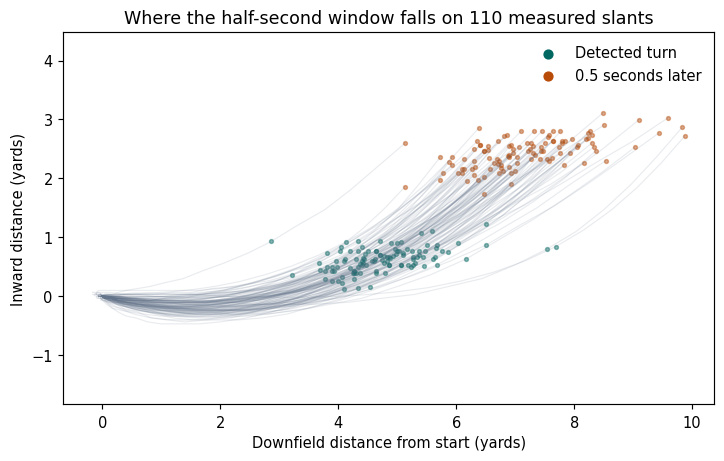

In [3]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for x, y, turn in paths:
    ax.plot(x[:turn + 6], y[:turn + 6], color="#64748b", alpha=.14, lw=.8)
    ax.scatter(x[turn], y[turn], s=7, color="#006761", alpha=.45)
    ax.scatter(x[turn+5], y[turn+5], s=7, color="#b84b08", alpha=.45)
for color, label in [("#006761", "Detected turn"), ("#b84b08", "0.5 seconds later")]:
    ax.scatter([], [], color=color, label=label)
ax.legend(frameon=False)
ax.set(xlabel="Downfield distance from start (yards)", ylabel="Inward distance (yards)",
       title=f"Where the half-second window falls on {len(paths)} measured slants")
ax.set_aspect("equal", adjustable="datalim")

fig.tight_layout()
plt.show()

*Figure 1. Each line is one left-slant attempt, aligned to its starting location. The two markers show where the speed comparison starts and ends. They identify a change of direction; an exact foot plant would require video.*

## 2. Compare the same receivers on the same NFL outcome
I use rookie regular-season routes against man coverage, including routes on which the receiver was never targeted. For each route, I subtract the typical separation for that route type in the 2023–24 data. A receiver’s outcome is their median remaining separation at pass release, measured in yards.

All three forecasts use the same 35 training receivers and the same 15 evaluation receivers at the primary 20-route cutoff. The first predicts the training average for everyone, the second adds dash time, and the third adds the slant measurement. Lower mean absolute error is better.

In [4]:
def game_routes(folder, wr):
    games = pd.read_csv(folder / "games.csv", usecols=["game_id", "season", "season_type"])
    reg = games.query("season_type == 'REG'")
    cols = ["game_id", "play_id", "nfl_id", "team_abbr", "possession_team", "route_ran",
            "team_coverage_man_zone", "play_nullified_by_penalty", "separation_at_pass_forward"]
    plays = pd.read_csv(folder / "player_play.csv", usecols=cols)
    plays = plays.merge(reg, on="game_id", validate="many_to_one").merge(
        wr[["nfl_id", "draft_year"]], on="nfl_id", validate="many_to_one")
    plays = plays.query("season == draft_year and team_abbr == possession_team and "
                        "team_coverage_man_zone == 'MAN_COVERAGE' and play_nullified_by_penalty == 'N'")
    plays = plays.dropna(subset=["route_ran", "separation_at_pass_forward"])
    plays = plays[plays.separation_at_pass_forward.ge(0)].copy()
    if plays.duplicated(["nfl_id", "game_id", "play_id"]).any():
        raise ValueError("Duplicate receiver-play records")
    # Centre separation by route type using earlier cohorts only.
    train = plays[plays.season < 2025]
    typical = train.groupby("route_ran").separation_at_pass_forward.median()
    plays["gap"] = plays.separation_at_pass_forward - plays.route_ran.map(typical)
    return plays.dropna(subset=["gap"]).groupby("nfl_id").gap.agg(
        routes="count", adjusted_gap="median").reset_index()


def forecast(train, test, features):
    def design(frame):
        return np.column_stack([np.ones(len(frame)), frame[features].to_numpy()])
    coef = np.linalg.lstsq(design(train), train.adjusted_gap, rcond=None)[0]
    return design(test) @ coef


def compare(data, minimum):
    eligible = data[data.routes >= minimum]
    train, test = eligible[eligible.draft_year < 2025], eligible[eligible.draft_year == 2025]
    if len(train) < 4 or len(test) < 2:
        raise ValueError("Insufficient eligible players")
    errors = np.array([abs(test.adjusted_gap - forecast(train, test, features)).to_numpy()
                       for features in ([], ["forty"], ["forty", "gain"])])
    difference = errors[1] - errors[2]
    rng = np.random.default_rng(2027)
    interval = np.quantile(rng.choice(difference, (5000, len(test)), replace=True).mean(axis=1),
                           [0.025, 0.975])
    print(f"{minimum} routes | train {len(train)}, test {len(test)} | "
          f"MAE {errors.mean(axis=1).round(4)} | dash minus combined "
          f"{difference.mean():+.4f}, interval {interval.round(4)}")
    return errors.mean(axis=1), len(test)



wr = pd.read_csv(folder / 'combine_results.csv').query("combine_position == 'WR'")
data = wr.merge(features, on=['nfl_id', 'draft_year'], validate='one_to_one')
data = data.merge(game_routes(folder, wr), on='nfl_id', validate='one_to_one').dropna(subset=['forty'])
for minimum in (10, 20, 30):
    errors, n = compare(data, minimum)
    if minimum == 20:
        scores, test_size = errors, n

10 routes | train 43, test 16 | MAE [0.1453 0.1972 0.1977] | dash minus combined -0.0005, interval [-0.0022  0.0016]
20 routes | train 35, test 15 | MAE [0.1346 0.1618 0.1748] | dash minus combined -0.0130, interval [-0.0356  0.0109]
30 routes | train 32, test 14 | MAE [0.1387 0.1675 0.1726] | dash minus combined -0.0051, interval [-0.0234  0.0144]


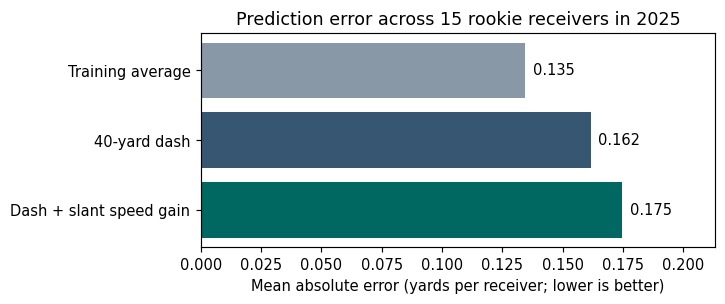

In [5]:
fig, ax = plt.subplots(figsize=(7, 3))
labels = ["Training average", "40-yard dash", "Dash + slant speed gain"]
bars = ax.barh(labels, scores, color=["#8998a6", "#375672", "#006761"])
ax.invert_yaxis()
ax.bar_label(bars, fmt="%.3f", padding=5)
ax.set_xlim(0, max(scores)*1.22)
ax.set(title=f"Prediction error across {test_size} rookie receivers in 2025",
       xlabel="Mean absolute error (yards per receiver; lower is better)")

fig.tight_layout()
plt.show()

*Figure 2. On 2025 rookies with at least 20 qualifying routes, the training average had the lowest error (0.135 yards). At minimums of 10 and 30 routes, adding slant speed gain also failed to improve on dash time.*

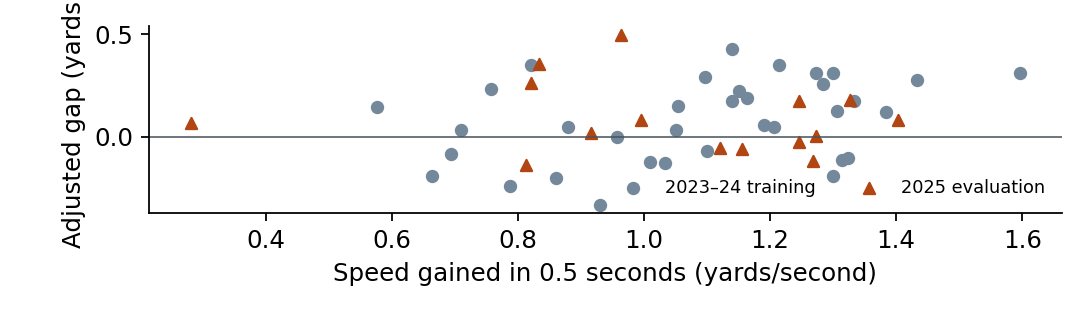

In [6]:
fig, ax = plt.subplots(figsize=(6.8, 1.95))
primary = data[data.routes >= 20]
for mask, color, label, marker in [
    (primary.draft_year < 2025, '#74889b', '2023–24 training', 'o'),
    (primary.draft_year == 2025, '#b14612', '2025 evaluation', '^')]:
    group = primary[mask]
    ax.scatter(group.gain, group.adjusted_gap, s=25, color=color, marker=marker, label=label)
ax.axhline(0, lw=.7, color='#49545b')
ax.legend(fontsize=8, frameon=False, ncol=2)
ax.set(xlabel='Speed gained in 0.5 seconds (yards/second)', ylabel='Adjusted gap (yards)')
fig.tight_layout()
plt.show()


## What a scout can take away
A small speed gain can mean two different things: the receiver was slow to accelerate, or the receiver carried so much speed through the break that little recovery was necessary. I’d review film of receivers with similar dash times and compare their entry and exit speeds before treating this measurement as a draft grade.

## How much confidence should we place in the result?
The estimated gain in accuracy from adding the slant metric was **−0.013 yards**. Its approximate 95% interval ran from **−0.036 to +0.011 yards**, resampling the 15 evaluation players with the training models fixed. Pre-snap cushion, defender quality and release timing could also affect separation. The 2025 cohort was examined in an earlier dash-time study, so a new draft class would be a stronger independent check.

[Reproducible Python script and standalone figures](https://github.com/maybesmdieko/NFL-BDB-Analysis/tree/main/slant)

## Slants against slants and a matched film example
Exploratory checks use players.csv for labels in addition to the four original inputs. The selected pair maximizes the entry-speed difference among eligible training receivers with a single recorded rep and gains within 0.05 yd/s. Selection did not use NFL outcomes.

All routes [] 0.1346
All routes ['forty'] 0.1618
All routes ['forty', 'gain'] 0.1748
All routes ['forty', 'gain', 'entry'] 0.1732
Marker -1 35 15 0.1653
Marker gain 35 15 0.1748
Marker 1 35 15 0.1806
Measured NFL slants 335 players 57 cushion available 334
NFL slant minimum 1 40 17
NFL slant minimum 5 23 7
Exploratory slant MAE [] 0.4753
Exploratory slant MAE ['forty'] 0.6762
Exploratory slant MAE ['forty', 'gain'] 0.6694
NFL slant minimum 10 9 1
NFL slant minimum 20 0 0
Cushion-adjusted slants 23 7 MAE [np.float64(0.3798), np.float64(0.3793), np.float64(0.3773)]
Andrei Iosivas entry/exit/gain [4.89 6.03 1.14] routes 26 adjusted separation 0.426
Demario Douglas entry/exit/gain [6.553 7.717 1.163] routes 92 adjusted separation 0.188


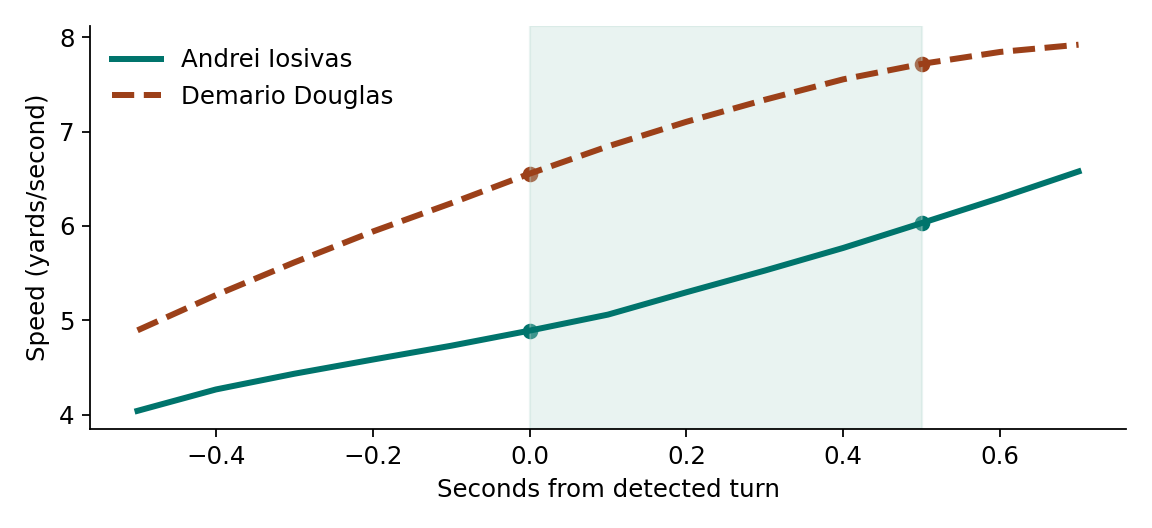

In [7]:
"""Exploratory checks. Run: python followup.py --data-dir /path/to/csvs"""
from itertools import combinations
from pathlib import Path
import argparse
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd



def followup(folder):
    wr = pd.read_csv(folder / "combine_results.csv").query("combine_position == 'WR'")
    names = pd.read_csv(folder / "players.csv", usecols=["nfl_id", "display_name"])
    chunks = pd.read_csv(folder / "combine_tracking.csv", chunksize=100000)
    drill = pd.concat(c.query("entity_type == 'PLAYER' and drill_type == 'SKILL_DRILLS_WR' "
                              "and drill_name == 'SLANT_ROUTE_LEFT'") for c in chunks)
    reps, traces = [], {}
    for (player, event), g in drill.groupby(["nfl_id", "event_id"]):
        measured = measure_attempt(g)
        if measured is None:
            continue
        gain, _, _, t = measured
        s = g.sort_values("time").s.to_numpy()
        row = dict(nfl_id=player, event=event, entry=s[t], gain=gain)
        for offset in (-1, 1):
            j = t + offset
            row[str(offset)] = s[j+5]-s[j] if 0 <= j and j+5 < len(s) else np.nan
        reps.append(row)
        traces[event] = (s, t)
    reps = pd.DataFrame(reps)
    feats = reps.groupby("nfl_id")[["gain", "entry", "-1", "1"]].median().reset_index()
    cohort = wr.merge(feats, on="nfl_id").merge(game_routes(folder, wr), on="nfl_id")
    cohort = cohort.dropna(subset=["forty"]).merge(names, on="nfl_id")
    main = cohort[cohort.routes >= 20]
    train, test = main[main.draft_year < 2025], main[main.draft_year == 2025]
    for cols in ([], ["forty"], ["forty","gain"], ["forty","gain","entry"]):
        print("All routes", cols, round(np.mean(abs(test.adjusted_gap-forecast(train,test,cols))),4))
    common = main.dropna(subset=["-1","1"])
    for key in ("-1","gain","1"):
        a,b = common[common.draft_year < 2025],common[common.draft_year == 2025]
        print("Marker", key,len(a),len(b),round(np.mean(abs(b.adjusted_gap-forecast(a,b,["forty",key]))),4))

    cols = ["game_id","play_id","nfl_id","route_ran","separation_at_pass_forward","cushion",
            "team_coverage_man_zone","possession_team","team_abbr","play_nullified_by_penalty"]
    plays = pd.read_csv(folder / "player_play.csv",usecols=cols)
    games = pd.read_csv(folder / "games.csv").query("season_type == 'REG'")
    sl = plays.merge(games[["game_id","season"]],on="game_id",validate="many_to_one")
    sl = sl.merge(cohort[["nfl_id","draft_year"]],on="nfl_id",validate="many_to_one")
    sl = sl.query("season == draft_year and route_ran == 'SLANT' and team_coverage_man_zone == 'MAN_COVERAGE'"
                  " and team_abbr == possession_team and play_nullified_by_penalty == 'N' and separation_at_pass_forward >= 0")
    assert not sl.duplicated(["game_id","play_id","nfl_id"]).any()
    summary = sl.groupby("nfl_id").agg(slants=("play_id","size"), gap=("separation_at_pass_forward","median"))
    same = cohort.merge(summary,on="nfl_id")
    print("Measured NFL slants",len(sl),"players",len(same),"cushion available",sl.cushion.count())
    for cutoff in (1,5,10,20):
        sub = same[same.slants >= cutoff].copy()
        sub["adjusted_gap"] = sub.gap
        a,b = sub[sub.draft_year<2025],sub[sub.draft_year==2025]
        print("NFL slant minimum",cutoff,len(a),len(b))
        if cutoff == 5 and len(b)>1:
            for cols in ([],["forty"],["forty","gain"]):
                print("Exploratory slant MAE",cols,round(np.mean(abs(b.gap-forecast(a,b,cols))),4))

    # Estimate the association with cushion only on training routes, then compare
    # receivers on separation relative to that pre-snap expectation.
    cush = sl.dropna(subset=["cushion"]).copy()
    old = cush[cush.season < 2025]
    slope, intercept = np.polyfit(old.cushion, old.separation_at_pass_forward, 1)
    cush["residual"] = cush.separation_at_pass_forward - (intercept + slope*cush.cushion)
    context = cush.groupby("nfl_id").residual.agg(["median","count"]).reset_index()
    ctx = cohort.merge(context,on="nfl_id").query("count >= 5").copy()
    ctx["adjusted_gap"] = ctx["median"]
    a,b = ctx[ctx.draft_year<2025],ctx[ctx.draft_year==2025]
    print("Cushion-adjusted slants",len(a),len(b),"MAE",[
        round(np.mean(abs(b.adjusted_gap-forecast(a,b,cols))),4)
        for cols in ([],["forty"],["forty","gain"])])

    # Select from training receivers with a single drill rep. Selection uses only
    # sensor measurements and eligibility, never NFL outcomes or names.
    one = reps[~reps.nfl_id.duplicated(keep=False)].merge(train,on="nfl_id",suffixes=("","_median"))
    pairs = [(a,b) for a,b in combinations(one.itertuples(),2) if abs(a.gain-b.gain)<=0.05]
    a,b = max(pairs,key=lambda pair:abs(pair[0].entry-pair[1].entry))
    fig,ax=plt.subplots(figsize=(7.2,3.3))
    for r,color,style in [(a,"#00746c","-"),(b,"#9c4019","--")]:
        s,t=traces[r.event]; times=(np.arange(len(s))-t)/10
        keep=(times>=-0.5)&(times<=0.7)
        ax.plot(times[keep],s[keep],style,color=color,label=r.display_name,linewidth=2.7)
        ax.scatter([0,.5],[r.entry,r.entry+r.gain],color=color)
        print(r.display_name,"entry/exit/gain",np.round([r.entry,r.entry+r.gain,r.gain],3),
              "routes",r.routes,"adjusted separation",round(r.adjusted_gap,3))
    ax.axvspan(0,.5,color="#bddbd4",alpha=.32)
    ax.set(xlabel="Seconds from detected turn",ylabel="Speed (yards/second)")
    ax.legend(frameon=False);fig.tight_layout()
    return fig



matched_figure = followup(folder)
plt.show()

Only seven 2025 receivers met the five-slant minimum. Accounting for cushion left about 0.002 yards of improvement over dash alone. Use the two receiver traces to choose film for review; more seasons are needed to judge performance.